### Add Synthetic noise from SWOT to simulation (snapshots field)

In [1]:
import netCDF4 as nc
import glob
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import xrft
from scipy.io import loadmat
import scipy.io as sio
from scipy.special import gamma, kv
from numpy.linalg import inv
# import cartopy.crs as ccrs
# import cartopy.feature as cfeature
from scipy.stats import chi2
import swot_analysis as swot
from matplotlib import pyplot as plt, animation
import h5py
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
import mpmath as mp
import datetime
from matplotlib import pyplot as plt, animation
import scipy.stats as stats
import pandas as pd
import math
import pickle
import zipfile
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
from scipy.fft import dct
from scipy.interpolate import interp1d
import time
import numpy.linalg as la
import warnings

In [2]:
with open('GSExtension_reselect_sim_snapshots.pkl', 'rb') as f:
    data_GS = pickle.load(f)
spectra_tot_combined_GS = data_GS['spectra_tot_combined']
ssha_tot_combined_GS    = data_GS['ssha_tot_combined']
lon_strip_tot_GS        = data_GS['lon_strip_tot']
lat_strip_tot_GS        = data_GS['lat_strip_tot']
ssha_mean2side_GS       = data_GS['ssha_mean2side']

In [54]:
# with open('Oleander_reselect_sim_snapshots.pkl', 'rb') as f:
#     data_Ol = pickle.load(f)
# spectra_tot_combined_Ol = data_Ol['spectra_tot_combined']
# ssha_tot_combined_Ol    = data_Ol['ssha_tot_combined']
# lon_strip_tot_Ol        = data_Ol['lon_strip_tot']
# lat_strip_tot_Ol        = data_Ol['lat_strip_tot']
# ssha_mean2side_Ol       = data_Ol['ssha_mean2side']

In [3]:
track_length = 350
dx = 2e3
k = np.fft.rfftfreq(track_length, dx)# rfft wave number cpm

In [4]:
def balanced_fit(k,A,k0,s0): # for balanced part
    return A/(1 + (k/k0)**(s0))

def matern_spec_new(k,s,A_s): # for small-scale part
    return 2*np.pi*A_s/((1+(100e3*k)**2)**(s/2))

def F_new(k,A,k0,s0,s,A_s):
    return np.log(balanced_fit(k,A,k0,s0)+ matern_spec_new(k,s,A_s)) 

def F_balanced(k,A,k0,s0):
    return np.log(balanced_fit(k,A,k0,s0))

In [5]:
#initial guesses
k0init = 8e-6
s0init = 5
ss = 1.2
As0 = 0.5
wnew = np.sqrt(k[1:])

In [6]:
seasonal = {
    'winter': [12, 1, 2],
    'spring': [3, 4, 5],
    'summer': [6, 7, 8],
    'fall':   [9, 10, 11]
}

In [7]:
def cholesky_decomp(M, name="Matrix", jitter=False):
    """ Performs the Cholesky decomposition of a matrix M and prints the time taken. 
        Optionally adds jitter to the diagonal if needed."""

    print(f"Performing Cholesky decomposition for {name}...")
    start_time = time.time()
    
    if jitter: 
        eps = 1e-8 * np.trace(M) / M.shape[0]
        M_jittered = M + eps * np.eye(M.shape[0]) # jitter the diagonal if we need it but turned off for now
        F = la.cholesky(M_jittered)
    
    else: 
        F = la.cholesky(M)
    
    print(f"Cholesky({name}) time: {time.time() - start_time:.4f} seconds")
    
    return F

In [8]:
def model_spectra(ssh_reshaped_model,track_length,dx = 2e3):
    window = np.sqrt(8./3.)*np.sin(np.pi*np.arange(track_length)/track_length)**2
    window_2d = np.broadcast_to(window.reshape(track_length, 1), (track_length, 25))
    
    ssh_reshaped_model_left = ssh_reshaped_model[:,5:30]
    ssh_reshaped_model_right = ssh_reshaped_model[:,39:39+25]
    # if np.isnan(ssh_reshaped_model_left).any() and np.isnan(ssh_reshaped_model_right).any(): 
    #     print("error, recheck selection")
        # continue 
    results = []
    for oneswath in [ssh_reshaped_model_left,ssh_reshaped_model_right]:
        if np.all(np.isnan(oneswath)):
            # print('nan swath')
            continue   # skip this array
        windowed_full = oneswath * window_2d
        amp_full = np.fft.rfft(windowed_full,axis=0)# rfft applied to windowed ssh [sample,y/2,x]
        ampsq_full = dx*(np.abs(amp_full))**2/track_length
        ampsq_1side_full = np.empty(ampsq_full.shape)
        ampsq_1side_full[:]=np.nan
        ampsq_1side_full[1:,:]=2*ampsq_full[1:,:]
        ampsq_1side_full[0,:] = ampsq_full[0,:]
        result = np.nanmean(ampsq_1side_full,axis = 1)#axis=tuple([0,2]))
        results.append(result)
    spec_1side_full = np.mean(results, axis=0)
    return spec_1side_full

### Seasonal fit

In [9]:
L = track_length * 2e3                        # domain length 
n = track_length                                      # number of samples 
# k_dct = np.arange(0, n//2 + 1) / L            # cycles/m
r_dct = np.arange(0, n//2 + 1) * L / n        # m

In [10]:
nx = track_length
ny = 69
x = np.outer(np.arange(1, nx+1), np.ones(ny)) * dx
y = np.outer(np.ones(nx), np.arange(1, ny+1)) * dx
dxx = np.subtract.outer(np.reshape(x,nx*ny),np.reshape(x,nx*ny))
dyy = np.subtract.outer(np.reshape(y,nx*ny),np.reshape(y,nx*ny))
r = np.hypot(dxx, dyy)

In [11]:
df_season_swot = spectra_tot_combined_GS[spectra_tot_combined_GS['month'].isin(seasonal['winter'])]
season_swotmean_spec = np.nanmean(np.stack(df_season_swot['spectrum']),axis = 0)

# df_season_swot = spectra_tot_combined_Ol[spectra_tot_combined_Ol['month'].isin(seasonal['winter'])]
# season_swotmean_spec = np.nanmean(np.stack(df_season_swot['spectrum']),axis = 0)

In [12]:
Ainit = season_swotmean_spec[1]
popcoef,popcov = curve_fit(F_new, k[1:], np.log(season_swotmean_spec[1:]), \
                                p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                bounds=([0, 0, 0, 0, 0], \
                                        [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)

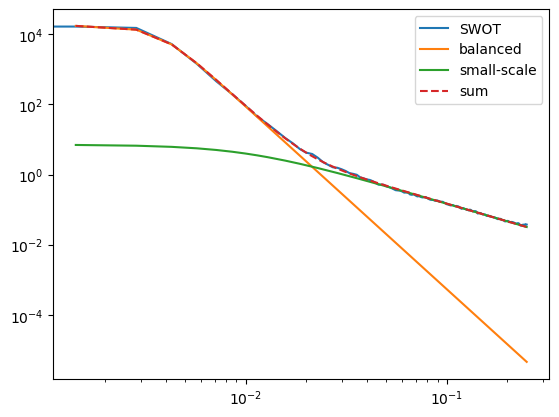

In [13]:
plt.loglog(k*1e3,season_swotmean_spec, label = 'SWOT')
plt.loglog(k[1:]*1e3,balanced_fit(k[1:],*popcoef[0:3]),label = 'balanced')
plt.loglog(k[1:]*1e3,matern_spec_new(k[1:],*popcoef[3:]),label = 'small-scale')
plt.loglog(k[1:]*1e3,matern_spec_new(k[1:],*popcoef[3:])+balanced_fit(k[1:],*popcoef[0:3]),'--',label = 'sum')
plt.legend()

In [14]:
S = matern_spec_new(k,*popcoef[3:]) 

In [15]:
C = dct(S, type=1) / (2 * L)

In [16]:
var_spec = (S[0]/2 + np.sum(S[1:-1]) + S[-1]/2) / L
var_cov = C[0]

print(f"Variance from spectrum:   {var_spec:.6f}")
print(f"Variance from covariance: {var_cov:.6f}")

Variance from spectrum:   0.000135
Variance from covariance: 0.000135


In [17]:
interp_fun = interp1d(r_dct, C, kind='linear', fill_value="extrapolate")
intep_cov = interp_fun(r)

In [18]:
F_c = cholesky_decomp(intep_cov)

Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.4150 seconds


In [19]:
df_season_sim = ssha_tot_combined_GS[ssha_tot_combined_GS['month'].isin(seasonal['winter'])]
# df_season_sim = ssha_tot_combined_Ol[ssha_tot_combined_Ol['month'].isin(seasonal['winter'])]

In [23]:
# df_season_sim.keys()

In [20]:
season_sim_spec = np.zeros((df_season_sim.shape[0],k.shape[0]))
for i, (_,row) in enumerate(df_season_sim.iterrows()):
    sshsnap = row['track_ssh_sim']
    h = F_c @ np.random.randn(track_length*ny)
    h_noise = h.reshape((nx, ny))
    ssh_recontruct = sshsnap + h_noise
    season_sim_spec[i,:] = model_spectra(ssh_recontruct,track_length)  

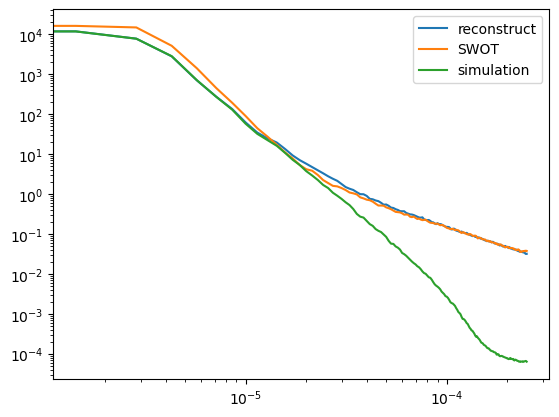

In [21]:
plt.loglog(k,np.mean(season_sim_spec,axis = 0),label = 'reconstruct')
plt.loglog(k,season_swotmean_spec,label = 'SWOT')
plt.loglog(k,np.mean(np.stack(df_season_sim['spectra_simulation']),axis = 0),label = 'simulation')
plt.legend()

In [ ]:
seasonal_rows = []
for season, months in seasonal.items():
    print(season)
    df_season_swot = spectra_tot_combined_GS[spectra_tot_combined_GS['month'].isin(months)]
    df_season_sim = ssha_tot_combined_GS[ssha_tot_combined_GS['month'].isin(months)]
    
    # df_season_swot = spectra_tot_combined_Ol[spectra_tot_combined_Ol['month'].isin(months)]
    # df_season_sim = ssha_tot_combined_Ol[ssha_tot_combined_Ol['month'].isin(months)]
    
    season_swotmean_spec = np.nanmean(np.stack(df_season_swot['spectrum']),axis = 0)
    Ainit = season_swotmean_spec[1]
    popcoef,popcov = curve_fit(F_new, k[1:], np.log(season_swotmean_spec[1:]), \
                                p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                bounds=([0, 0, 0, 0, 0], \
                                        [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)
    S = matern_spec_new(k,*popcoef[3:]) 
    C = dct(S, type=1) / (2 * L)
    interp_fun = interp1d(r_dct, C, kind='linear', fill_value="extrapolate")
    intep_cov = interp_fun(r)
    F_c = cholesky_decomp(intep_cov)
    season_sim_spec = np.zeros((df_season_sim.shape[0],k.shape[0]))
    for i, (_,row) in enumerate(df_season_sim.iterrows()):
        sshsnap = row['track_ssh_sim']
        h = F_c @ np.random.randn(track_length*ny)
        h_noise = h.reshape((nx, ny))
        ssh_recontruct = sshsnap + h_noise
        season_sim_spec[i,:] = model_spectra(ssh_recontruct,track_length)  
    reconstruct_sim = np.mean(season_sim_spec,axis = 0)
    seasonal_rows.append({
        "season": season,
        "reconstruct_sim": reconstruct_sim,
    })   

winter
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.0599 seconds
spring
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.4870 seconds
summer


In [27]:
reconstruct_sim_GS = pd.DataFrame(seasonal_rows)
# reconstruct_sim_Ol = pd.DataFrame(seasonal_rows)

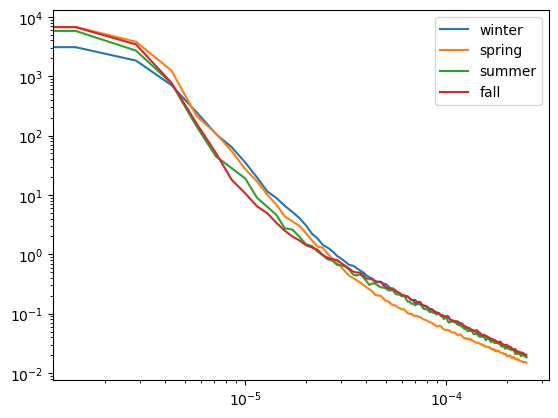

In [28]:
for i,row in reconstruct_sim_Ol.iterrows():
    plt.loglog(k,row['reconstruct_sim'],label = row['season'])
plt.legend()

In [29]:
# d = {'reconstruct_sim_GS':reconstruct_sim_GS}
# np.save('spectra_sim_snapshots_noise_synthetic.npy', d,allow_pickle=True)

In [31]:
# d = np.load('spectra_sim_snapshots_noise_synthetic.npy', allow_pickle=True).item()
# d["reconstruct_sim_Ol"] = reconstruct_sim_Ol
# np.save('spectra_sim_snapshots_noise_synthetic.npy', d,allow_pickle=True)

### Monthly spectral fit

In [32]:
monthly_rows = []
for month in range(1,13):
    print(month)
    # df_month_swot = spectra_tot_combined_GS[spectra_tot_combined_GS['month'] == month]
    # df_month_sim = ssha_tot_combined_GS[ssha_tot_combined_GS['month'] == month]

    df_month_swot = spectra_tot_combined_Ol[spectra_tot_combined_Ol['month'] == month]
    df_month_sim = ssha_tot_combined_Ol[ssha_tot_combined_Ol['month'] == month]
    month_swotmean_spec = np.nanmean(np.stack(df_month_swot['spectrum']),axis = 0)
    Ainit = month_swotmean_spec[1]
    popcoef,popcov = curve_fit(F_new, k[1:], np.log(month_swotmean_spec[1:]), \
                                p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                bounds=([0, 0, 0, 0, 0], \
                                        [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)
    S = matern_spec_new(k,*popcoef[3:]) 
    C = dct(S, type=1) / (2 * L)
    interp_fun = interp1d(r_dct, C, kind='linear', fill_value="extrapolate")
    intep_cov = interp_fun(r)
    F_c = cholesky_decomp(intep_cov)
    month_sim_spec = np.zeros((df_month_sim.shape[0],k.shape[0]))
    for i, (_,row) in enumerate(df_month_sim.iterrows()):
        sshsnap = row['track_ssh_sim']
        h = F_c @ np.random.randn(track_length*ny)
        h_noise = h.reshape((nx, ny))
        ssh_recontruct = sshsnap + h_noise
        month_sim_spec[i,:] = model_spectra(ssh_recontruct,track_length)  
    reconstruct_sim_monthly = np.mean(month_sim_spec,axis = 0)
    monthly_rows.append({
        "month": month,
        "reconstruct_sim": reconstruct_sim_monthly,
    })   

1
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.2097 seconds
2
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 26.2722 seconds
3
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.0642 seconds
4
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.2426 seconds
5
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.2425 seconds
6
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.0877 seconds
7
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.1429 seconds
8
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.3084 seconds
9
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.0682 seconds
10
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.2157 seconds
11
Performing Cholesky decomposition for Matrix...
Cholesky(Matrix) time: 25.1628 seconds
12
Performing Chole

In [33]:
# reconstruct_sim_GS_monthly = pd.DataFrame(monthly_rows)
reconstruct_sim_Ol_monthly = pd.DataFrame(monthly_rows)

In [39]:
# d = {'reconstruct_sim_GS_monthly':reconstruct_sim_GS_monthly}
# np.save('spectra_sim_snapshots_noise_synthetic_monthly.npy', d,allow_pickle=True)

In [37]:
# d = np.load('spectra_sim_snapshots_noise_synthetic_monthly.npy', allow_pickle=True).item()
# d["reconstruct_sim_Ol_monthly"] = reconstruct_sim_Ol_monthly 

In [38]:
# np.save('spectra_sim_snapshots_noise_synthetic_monthly.npy', d, allow_pickle=True)

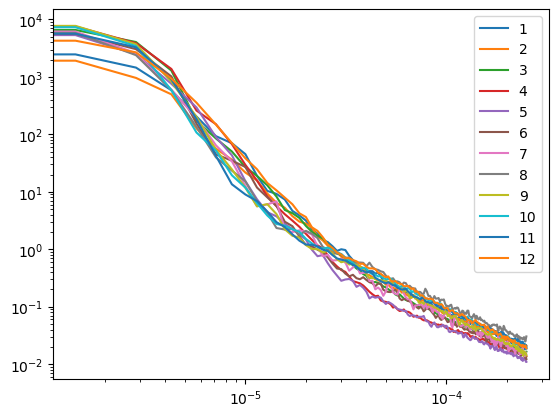

In [34]:
# for i, row in reconstruct_sim_GS_monthly.iterrows():
for i, row in reconstruct_sim_Ol_monthly.iterrows():
    plt.loglog(k,row['reconstruct_sim'],label = row['month'])
plt.legend()

In [40]:
slopemonthly_simnz = np.empty((12,))
slopemonthly_simnz[:] = np.nan 
unctmonthly_simnz = np.empty((12,))
unctmonthly_simnz[:] = np.nan
coeftot_simnz = np.empty((12,5))
coeftot_simnz[:] = np.nan
# rows = []
# for i,row in reconstruct_sim_GS_monthly.iterrows():
for i,row in reconstruct_sim_Ol_monthly.iterrows():
    spec = row['reconstruct_sim']
    Ainit = spec[1]
    try:
        coef_simnz,covn_simnz = curve_fit(F_new, k[1:], np.log(spec[1:]), \
                            p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                            bounds=([0, 0, 0, 0, 0], \
                                    [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)
        slopemonthly_simnz[i] = coef_simnz[2]
        unctmonthly_simnz[i] = np.sqrt(covn_simnz[2,2])
        coeftot_simnz[i,:] = coef_simnz
    except Exception:
        continue  # Skip to the next iteration if curve_fit fails
# reconstruct_sim_GS = pd.DataFrame(rows)

### Check uncertainties

In [42]:
# num_simGS = (
#     ssha_tot_combined_GS
#     .drop_duplicates(subset=["month", "dates", "position"])
#     .groupby("month")
#     .size()
# )

num_simOl = (
    ssha_tot_combined_Ol
    .drop_duplicates(subset=["month", "dates", "position"])
    .groupby("month")
    .size()
)

In [43]:
# lowerm_simGSnz = np.empty((12,))
# upperm_simGSnz = np.empty((12,))
# medianm_simGSnz = np.empty((12,))

lowerm_simOlnz = np.empty((12,))
upperm_simOlnz = np.empty((12,))
medianm_simOlnz = np.empty((12,))
B = 1000          # number of Monte Carlo samples

In [45]:
for m in range(0,12):
    # nu = 2 * num_simGS[m+1]     # if 20 independent spectra, each with 2 dof
    nu = 2 * num_simOl[m+1]

    # reconstruct_sim_spec = reconstruct_sim_GS_monthly['reconstruct_sim'][m]
    reconstruct_sim_spec = reconstruct_sim_Ol_monthly['reconstruct_sim'][m]
    
    popcoefmGSnz,popcovmGSnz = curve_fit(F_new, k[1:], np.log(reconstruct_sim_spec[1:]), \
                                    p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                    bounds=([0, 0, 0, 0, 0], \
                                            [1e9, 1e9, 1e9, 1e9, 1e9]),maxfev=5000)
    P_fitnz = matern_spec_new(k[1:],*popcoefmGSnz[3:])+balanced_fit(k[1:],*popcoefmGSnz[0:3])

    
    theta_bootnz = []
    
    for b in range(B):

        try:             
            noise = np.random.chisquare(nu, size=len(k[1:])) / nu
            P_synthetic = P_fitnz * noise
            popcoefmnz,_ = curve_fit(F_new, k[1:], np.log(P_synthetic), \
                                        p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                        bounds=([0, 0, 0,0,0], \
                                                [1e9, 1e9,1e9,1e9,1e9]),maxfev=5000)
    
            # theta_boot.append(popcoefm)
            theta_bootnz.append(popcoefmnz)
        except RuntimeError:
            continue
    
    
    theta_bootnz = np.array(theta_bootnz)
    slope_bootnz = theta_bootnz[:,2] 
    
    # lowerm_simGSnz[m] = np.percentile(slope_bootnz, 2.5)
    # upperm_simGSnz[m] = np.percentile(slope_bootnz, 97.5)
    # medianm_simGSnz[m] = np.percentile(slope_bootnz, 50)

    lowerm_simOlnz[m] = np.percentile(slope_bootnz, 2.5)
    upperm_simOlnz[m] = np.percentile(slope_bootnz, 97.5)
    medianm_simOlnz[m] = np.percentile(slope_bootnz, 50)

Text(0, 0.5, 'Spectral slope')

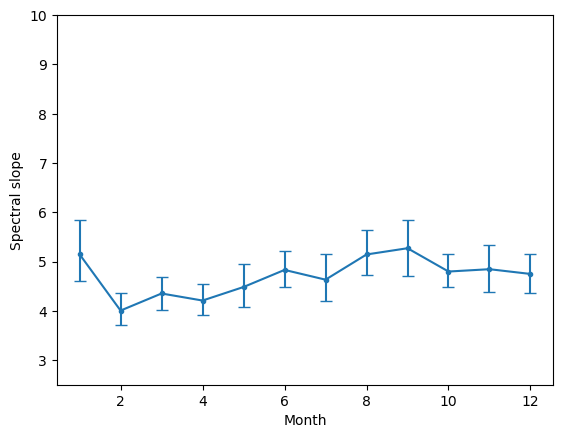

In [64]:
plt.errorbar(range(1,13),slopemonthly_simnz,\
             np.vstack([slopemonthly_simnz - lowerm_simGSnz, upperm_simGSnz - slopemonthly_simnz]),fmt='.-',capsize=4)
plt.ylim((2.5,10))
# plt.legend()
plt.xlabel('Month')
plt.ylabel('Spectral slope')

Text(0, 0.5, 'Spectral slope')

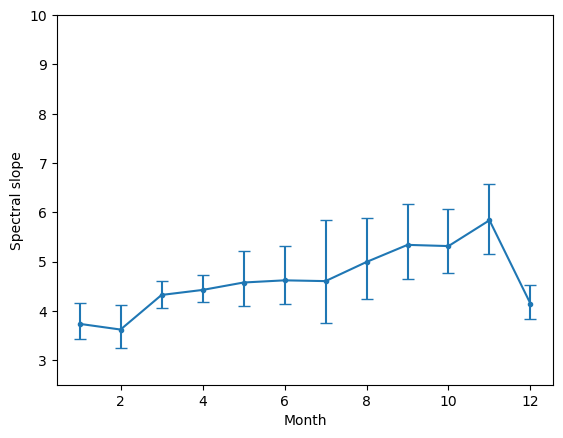

In [46]:
plt.errorbar(range(1,13),slopemonthly_simnz,\
             np.vstack([slopemonthly_simnz - lowerm_simOlnz, upperm_simOlnz - slopemonthly_simnz]),fmt='.-',capsize=4)
plt.ylim((2.5,10))
# plt.legend()
plt.xlabel('Month')
plt.ylabel('Spectral slope')

In [49]:
# d = {'slopemonthly_simGSnz':slopemonthly_simnz,'lowerm_simGSnz':lowerm_simGSnz,'upperm_simGSnz':upperm_simGSnz}
# np.save('slope_reconstructed_synthetic.npy', d,allow_pickle=True)

In [50]:
# d = np.load('slope_reconstructed_synthetic.npy', allow_pickle=True).item()
# d["slopemonthly_simOlnz"] = slopemonthly_simnz
# d["lowerm_simOlnz"] = lowerm_simOlnz
# d["upperm_simOlnz"] = upperm_simOlnz

In [51]:
# np.save('slope_reconstructed_synthetic.npy', d,allow_pickle=True)